Dataset Shape: (50000, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews:
418

Dataset Shape After Removing Duplicates: (49582, 2)
Duplicates After Removing: 0

Sentiment Distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


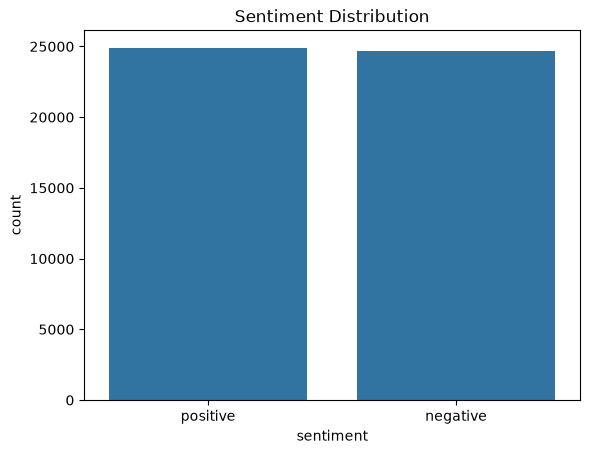


Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Cleaned Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this

Encoded Labels:
  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1

Label Distribution:
label
1    24884
0    24698
Name: count, dtype: int64

Training Samples: 34707
Validation Samples: 7437
Testing Samples: 7438

Original Review:
I work in a library and expected to like this movie when it came ou

In [1]:
from Data_exploration import (
    X_train_pad,
    X_val_pad,
    X_test_pad,
    y_train,
    y_val,
    y_test,
    MAX_WORDS,
    MAX_LEN
)

In [2]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

In [3]:
model_rnn = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128
    ),

    SimpleRNN(
        units=64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        units=1,
        activation="sigmoid"
    )
])

model_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,417 (9.81 MB)

 Trainable params: 2,572,417 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model_rnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [5]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [6]:
history_rnn = model_rnn.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 33s 57ms/step - accuracy: 0.4996 - loss: 0.7038 - val_accuracy: 0.4990 - val_loss: 0.6937
Epoch 2/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 28s 52ms/step - accuracy: 0.5494 - loss: 0.6747 - val_accuracy: 0.5022 - val_loss: 0.7140
Epoch 3/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 30s 55ms/step - accuracy: 0.6049 - loss: 0.5849 - val_accuracy: 0.4942 - val_loss: 0.7632


In [7]:
test_loss, test_accuracy = model_rnn.evaluate(
    X_test_pad,
    y_test
)

print("RNN Test Loss:", test_loss)
print("RNN Test Accuracy:", test_accuracy)

233/233 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.4987 - loss: 0.6933
RNN Test Loss: 0.6933294534683228
RNN Test Accuracy: 0.4986555576324463


In [8]:
from sklearn.metrics import classification_report

y_pred_prob = model_rnn.predict(X_test_pad)

y_pred_rnn = (y_pred_prob >= 0.5).astype(int).flatten()

print(classification_report(
    y_test,
    y_pred_rnn,
    target_names=["Negative", "Positive"]
))

233/233 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step
              precision    recall  f1-score   support

    Negative       0.47      0.06      0.11      3705
    Positive       0.50      0.93      0.65      3733

    accuracy                           0.50      7438
   macro avg       0.49      0.50      0.38      7438
weighted avg       0.49      0.50      0.38      7438



In [16]:
print("Training Accuracy:", history_rnn.history["accuracy"])
print("Validation Accuracy:", history_rnn.history["val_accuracy"])

print("Training Loss:", history_rnn.history["loss"])
print("Validation Loss:", history_rnn.history["val_loss"])

Training Accuracy: [0.4995534121990204, 0.5493992567062378, 0.6048635840415955]
Validation Accuracy: [0.4989915192127228, 0.5022186636924744, 0.49415087699890137]
Training Loss: [0.7037616968154907, 0.6747435927391052, 0.5849345922470093]
Validation Loss: [0.6937471628189087, 0.7139526009559631, 0.7632054090499878]


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns


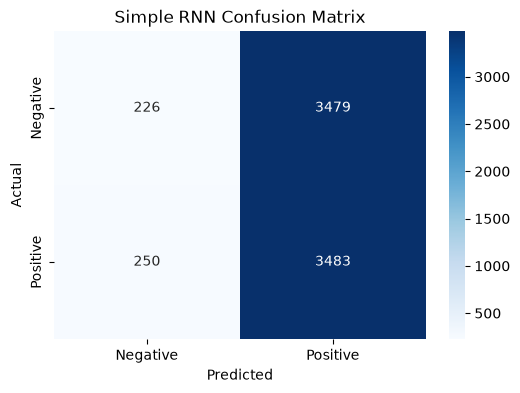

In [13]:
from sklearn.metrics import confusion_matrix

cm_rnn = confusion_matrix(y_test, y_pred_rnn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Simple RNN Confusion Matrix")

plt.show()

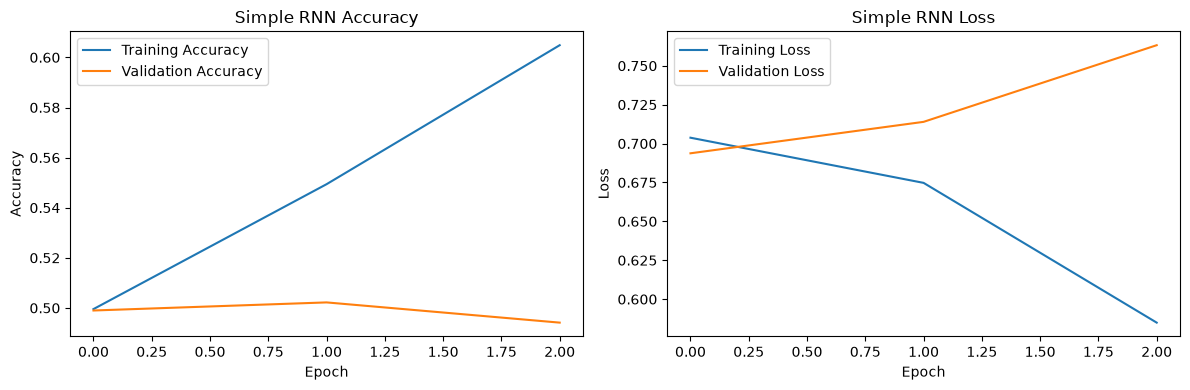

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history_rnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_rnn.history["val_accuracy"], label="Validation Accuracy")

plt.title("Simple RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_rnn.history["loss"], label="Training Loss")
plt.plot(history_rnn.history["val_loss"], label="Validation Loss")

plt.title("Simple RNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
import os

os.makedirs("models", exist_ok=True)

model_rnn.save("models/simple_rnn_model.keras")